# Evaluate fine-tuned models on the test set

Discovers every model folder next to this notebook that contains a `*_fine_tuning.pth` (full model) or
`*_fine_tuning.pt` (state dict) checkpoint, evaluates it on `data/dataset/test` and reports:

- overall metrics (accuracy, balanced accuracy, macro/weighted precision/recall/F1, top-k accuracy, ...)
- per-class metrics incl. the class each one is most often confused with
- confusion matrices (counts and row-normalised)
- the most frequent confusions
- example images of false classifications

Predictions are cached per model in `<model folder>/test_evaluation/` so re-running the notebook is fast.
New model folders are picked up automatically.

In [15]:
import os
import glob
import json
import random
import warnings

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from IPython.display import display, Markdown
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, cohen_kappa_score, confusion_matrix,
    log_loss, precision_recall_fscore_support, top_k_accuracy_score,
)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

## Configuration

In [16]:
# Folder containing one sub-folder per trained model (this notebook's folder)
MODELS_ROOT = os.path.abspath(".")
# Repository root: model/results/training -> ../../..
REPO_ROOT = os.path.abspath(os.path.join(MODELS_ROOT, "..", "..", ".."))
TEST_DIR = os.path.join(REPO_ROOT, "data", "dataset", "test")

CHECKPOINT_SUFFIX = "_fine_tuning"
BATCH_SIZE = 64
NUM_WORKERS = 0          # >0 can be problematic inside Jupyter on Windows
FORCE_RERUN = False      # True -> ignore cached predictions
SAVE_FIGURES = True      # store plots in <model folder>/test_evaluation/
N_ERROR_EXAMPLES = 24    # number of images in the misclassification grids
SEED = 42

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print("Models root:", MODELS_ROOT)
print("Test dir:   ", TEST_DIR, "(exists)" if os.path.isdir(TEST_DIR) else "(MISSING!)")
print("Device:     ", DEVICE)

Models root: c:\Users\Jan Stenkamp\Documents\Birdiary\TinyBirdiary\bird-species-classification\model\results\training
Test dir:    c:\Users\Jan Stenkamp\Documents\Birdiary\TinyBirdiary\bird-species-classification\data\dataset\test (exists)
Device:      cuda


## Discover models

In [17]:
def discover_models(root=MODELS_ROOT, suffix=CHECKPOINT_SUFFIX):
    """Find all model folders with a fine-tuning checkpoint. Prefers the full model (.pth) over the state dict (.pt)."""
    models = {}
    for folder in sorted(glob.glob(os.path.join(root, "*"))):
        if not os.path.isdir(folder):
            continue
        for ext in (".pth", ".pt"):  # order = preference
            hits = sorted(glob.glob(os.path.join(folder, f"*{suffix}{ext}")))
            if hits:
                name = os.path.basename(hits[0])[: -len(suffix + ext)]
                yaml_path = os.path.join(folder, f"{name}.yaml")
                cfg = {}
                if os.path.exists(yaml_path):
                    with open(yaml_path) as f:
                        cfg = yaml.safe_load(f) or {}
                models[name] = {"name": name, "folder": folder, "checkpoint": hits[0], "config": cfg}
                break
    return models


MODELS = discover_models()
for m in MODELS.values():
    print(f"{m['name']:<30} {m['config'].get('model_type', '?'):<15} {os.path.relpath(m['checkpoint'], MODELS_ROOT)}")
if not MODELS:
    print("No models found!")

birdiary-v2                    squeezenet      birdiary-v2\birdiary-v2_fine_tuning.pth
birdiary-v2-mobilenet          mobilenetv2     birdiary-v2-mobilenet\birdiary-v2-mobilenet_fine_tuning.pth
birdiary-v2-squeezenet         mobilenet       birdiary-v2-squeezenet\birdiary-v2-squeezenet_fine_tuning.pth


## Model loading & preprocessing

`.pth` files contain the full pickled model. `.pt` files only contain the state dict, so the architecture is
rebuilt from `model_type` in the model's YAML (mirrors `model/training/model_factory.py`, without downloading
pretrained weights). Only the deterministic transforms of the training config (resize, normalize) are used for
evaluation; random augmentations are skipped.

In [18]:
def _relu6_to_relu(model):
    for name, child in model.named_children():
        if isinstance(child, nn.ReLU6):
            setattr(model, name, nn.ReLU(inplace=child.inplace))
        else:
            _relu6_to_relu(child)
    return model


def build_architecture(model_type, num_classes):
    """Rebuild the architecture used in model_factory.py (random init, weights are loaded afterwards)."""
    tv = torchvision.models
    if model_type == "squeezenet":
        m = tv.squeezenet1_1(weights=None)
        m.classifier[1] = nn.Conv2d(512, num_classes, kernel_size=1)
    elif model_type == "mobilenetv2":
        m = _relu6_to_relu(tv.mobilenet_v2(weights=None))
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    elif model_type == "mobilenetv3":
        m = _relu6_to_relu(tv.mobilenet_v3_small(weights=None))
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
    elif model_type == "efficientnet":
        m = tv.efficientnet_v2_s(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    elif model_type == "efficientnet_b0":
        m = tv.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    elif model_type == "densenet":
        m = tv.densenet121(weights=None)
        m.classifier = nn.Linear(m.classifier.in_features, num_classes)
    elif model_type == "shufflenet":
        m = tv.shufflenet_v2_x1_5(weights=None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif model_type == "mnasnet":
        m = tv.mnasnet0_5(weights=None)
        m.classifier = nn.Linear(m.classifier[1].in_features, num_classes)
    else:
        raise ValueError(f"Cannot rebuild architecture for model_type={model_type!r}")
    return m


def load_model(entry, num_classes):
    ckpt = entry["checkpoint"]
    if ckpt.endswith(".pth"):
        model = torch.load(ckpt, map_location="cpu", weights_only=False)
        if isinstance(model, nn.DataParallel):
            model = model.module
    else:
        state = torch.load(ckpt, map_location="cpu")
        state = {k.removeprefix("module."): v for k, v in state.items()}
        model = build_architecture(entry["config"].get("model_type"), num_classes)
        model.load_state_dict(state)
    return model.to(DEVICE).eval()


def build_eval_transform(cfg):
    """Deterministic part of the first dataset's transforms in the training config."""
    size, mean, std = (224, 224), [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
    datasets_cfg = cfg.get("datasets") or [{}]
    for t in datasets_cfg[0].get("transforms", []):
        if isinstance(t, dict) and "resize" in t:
            size = (t["resize"]["height"], t["resize"]["width"])
        if isinstance(t, dict) and "normalize" in t:
            mean = t["normalize"].get("mean", mean)
            std = t["normalize"].get("std", std)
    return transforms.Compose([
        transforms.Resize(size),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

## Inference (cached)

In [19]:
def eval_dir(entry):
    d = os.path.join(entry["folder"], "test_evaluation")
    os.makedirs(d, exist_ok=True)
    return d


@torch.no_grad()
def predict(entry, force=FORCE_RERUN):
    """Return dict with probs, labels, paths, class_names. Cached as npz in the model folder."""
    cache = os.path.join(eval_dir(entry), f"{entry['name']}_test_predictions.npz")
    if os.path.exists(cache) and not force and os.path.getmtime(cache) > os.path.getmtime(entry["checkpoint"]):
        data = np.load(cache, allow_pickle=False)
        print(f"[{entry['name']}] loaded cached predictions from {os.path.relpath(cache, MODELS_ROOT)}")
        return {k: data[k] for k in data.files} | {"class_names": list(data["class_names"])}

    dataset = datasets.ImageFolder(TEST_DIR, transform=build_eval_transform(entry["config"]))
    class_names = dataset.classes
    model = load_model(entry, len(class_names))

    # Sanity check: number of outputs must match number of test classes
    dummy = next(iter(DataLoader(dataset, batch_size=1)))[0].to(DEVICE)
    n_out = model(dummy).shape[1]
    if n_out != len(class_names):
        raise ValueError(f"Model has {n_out} outputs but test set has {len(class_names)} classes")

    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda")
    all_probs, all_labels = [], []
    n_batches = len(loader)
    for i, (images, labels) in enumerate(loader):
        logits = model(images.to(DEVICE, non_blocking=True))
        all_probs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
        all_labels.append(labels.numpy())
        if (i + 1) % 20 == 0 or i + 1 == n_batches:
            print(f"\r[{entry['name']}] batch {i + 1}/{n_batches}", end="")
    print()

    result = {
        "probs": np.concatenate(all_probs),
        "labels": np.concatenate(all_labels),
        "paths": np.array([p for p, _ in dataset.samples]),
        "class_names": class_names,
    }
    np.savez_compressed(cache, probs=result["probs"], labels=result["labels"],
                        paths=result["paths"], class_names=np.array(class_names))
    return result

## Metrics

In [20]:
def compute_metrics(res):
    probs, y = res["probs"], res["labels"]
    names = res["class_names"]
    n = len(names)
    pred = probs.argmax(1)
    labels = np.arange(n)

    overall = {
        "n_test_images": len(y),
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "top3_accuracy": top_k_accuracy_score(y, probs, k=3, labels=labels),
        "top5_accuracy": top_k_accuracy_score(y, probs, k=5, labels=labels),
        "cohen_kappa": cohen_kappa_score(y, pred),
        "log_loss": log_loss(y, np.clip(probs, 1e-7, 1), labels=labels),
    }
    for avg in ("macro", "weighted"):
        p, r, f, _ = precision_recall_fscore_support(y, pred, average=avg, labels=labels, zero_division=0)
        overall |= {f"{avg}_precision": p, f"{avg}_recall": r, f"{avg}_f1": f}

    cm = confusion_matrix(y, pred, labels=labels)
    p, r, f, s = precision_recall_fscore_support(y, pred, labels=labels, zero_division=0)
    off = cm.copy()
    np.fill_diagonal(off, 0)
    top_conf = off.argmax(1)
    per_class = pd.DataFrame({
        "support": s,
        "predicted": cm.sum(0),
        "precision": p,
        "recall": r,
        "f1": f,
        "mean_conf_correct": [probs[(y == i) & (pred == i), i].mean() if ((y == i) & (pred == i)).any() else np.nan
                              for i in labels],
        "n_errors": off.sum(1),
        "most_confused_with": [names[j] if off[i, j] > 0 else "-" for i, j in enumerate(top_conf)],
        "share_of_class": [off[i, j] / s[i] if s[i] else 0 for i, j in enumerate(top_conf)],
    }, index=pd.Index(names, name="class"))

    # Most frequent (true -> predicted) confusions
    ti, pi = np.nonzero(off)
    pairs = pd.DataFrame({
        "true": [names[i] for i in ti],
        "predicted": [names[j] for j in pi],
        "count": off[ti, pi],
        "share_of_true_class": off[ti, pi] / s[ti],
    }).sort_values("count", ascending=False).reset_index(drop=True)

    return {"overall": overall, "per_class": per_class, "cm": cm, "pairs": pairs, "pred": pred}

## Plotting helpers

In [21]:
def _save(fig, entry, suffix):
    if SAVE_FIGURES:
        fig.savefig(os.path.join(eval_dir(entry), f"{entry['name']}_{suffix}.png"), dpi=150, bbox_inches="tight")


def plot_confusion_matrices(entry, res, met):
    names = res["class_names"]
    cm = met["cm"]
    cm_norm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    size = max(10, 0.55 * len(names))

    # Counts
    fig, ax = plt.subplots(figsize=(size, size * 0.85))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=names, yticklabels=names,
                linewidths=0.5, linecolor="white", cbar_kws={"label": "images", "shrink": 0.6},
                annot_kws={"size": 7}, ax=ax)
    ax.set(xlabel="Predicted", ylabel="True", title=f"{entry['name']} - confusion matrix (counts)")
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    fig.tight_layout()
    _save(fig, entry, "test_confusion_matrix_counts")
    plt.show()

    # Row-normalised (diagonal = recall); zeros hidden to keep it readable
    pct = np.round(cm_norm * 100).astype(int)
    annot = np.where(pct >= 1, pct.astype(str), "")
    fig, ax = plt.subplots(figsize=(size, size * 0.85))
    sns.heatmap(cm_norm * 100, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=100,
                xticklabels=names, yticklabels=names, linewidths=0.5, linecolor="white",
                cbar_kws={"label": "% of true class", "shrink": 0.6}, annot_kws={"size": 7}, ax=ax)
    ax.set(xlabel="Predicted", ylabel="True", title=f"{entry['name']} - confusion matrix (% of true class, diagonal = recall)")
    plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    fig.tight_layout()
    _save(fig, entry, "test_confusion_matrix_normalized")
    plt.show()


def plot_per_class(entry, met):
    df = met["per_class"].sort_values("f1")
    y = np.arange(len(df))
    h = 0.27
    fig, ax = plt.subplots(figsize=(10, max(6, 0.38 * len(df))))
    colors = {"precision": "#4C78A8", "recall": "#F58518", "f1": "#54A24B"}
    for k, (col, c) in enumerate(colors.items()):
        ax.barh(y + (1 - k) * h, df[col], height=h, color=c, label=col, edgecolor="white", linewidth=0.5)
    ax.set_yticks(y, [f"{c}  (n={s})" for c, s in zip(df.index, df["support"])])
    ax.set_xlim(0, 1.0)
    ax.axvline(met["overall"]["accuracy"], color="0.4", ls="--", lw=1, label="overall accuracy")
    ax.grid(axis="x", color="0.9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_title(f"{entry['name']} - per-class metrics (sorted by F1)", pad=28)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=4, frameon=False)
    fig.tight_layout()
    _save(fig, entry, "test_per_class_metrics")
    plt.show()


def plot_top_confusions(entry, met, top=20):
    df = met["pairs"].head(top).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(df))))
    ax.barh([f"{t}  ->  {p}" for t, p in zip(df["true"], df["predicted"])], df["count"],
            color="#4C78A8", height=0.7)
    for i, (c, s) in enumerate(zip(df["count"], df["share_of_true_class"])):
        ax.text(c, i, f" {c} ({s:.0%})", va="center", fontsize=8, color="0.25")
    ax.grid(axis="x", color="0.9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.set(xlabel="number of test images (share of true class)", title=f"{entry['name']} - {top} most frequent confusions (true -> predicted)")
    fig.tight_layout()
    _save(fig, entry, "test_top_confusions")
    plt.show()

## Misclassification examples

In [22]:
def show_misclassified(entry, res, met, n=N_ERROR_EXAMPLES, mode="confident",
                       true_class=None, pred_class=None, cols=6, save_suffix=None):
    """Show a grid of misclassified test images.

    mode: "confident" (highest wrong-class confidence first), "uncertain" (lowest first) or "random".
    true_class / pred_class: optionally restrict to errors of a given true and/or predicted class name.
    """
    probs, y, paths = res["probs"], res["labels"], res["paths"]
    names = res["class_names"]
    pred = met["pred"]
    idx = np.nonzero(pred != y)[0]
    if true_class is not None:
        idx = idx[y[idx] == names.index(true_class)]
    if pred_class is not None:
        idx = idx[pred[idx] == names.index(pred_class)]
    if len(idx) == 0:
        print("No matching misclassifications.")
        return

    conf = probs[idx, pred[idx]]
    if mode == "confident":
        idx = idx[np.argsort(-conf)]
    elif mode == "uncertain":
        idx = idx[np.argsort(conf)]
    else:
        idx = np.random.default_rng(SEED).permutation(idx)
    n_match = len(idx)
    idx = idx[:n]

    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 2.8, rows * 3.2), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idx):
        with Image.open(paths[i]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"true: {names[y[i]]}\npred: {names[pred[i]]} ({probs[i, pred[i]]:.0%})\n"
                     f"p(true) = {probs[i, y[i]]:.0%}", fontsize=8)
    filt = " ".join(x for x in [f"true={true_class}" if true_class else "", f"pred={pred_class}" if pred_class else ""] if x)
    fig.suptitle(f"{entry['name']} - misclassified ({mode}{', ' + filt if filt else ''}); "
                 f"showing {len(idx)} of {n_match} errors", fontsize=11)
    fig.tight_layout()
    if save_suffix:
        _save(fig, entry, save_suffix)
    plt.show()

## Run the evaluation for all models

In [23]:
RESULTS = {}
for name, entry in MODELS.items():
    res = predict(entry)
    met = compute_metrics(res)
    RESULTS[name] = {"entry": entry, "res": res, "met": met}

    out = eval_dir(entry)
    met["per_class"].to_csv(os.path.join(out, f"{name}_test_per_class_metrics.csv"))
    met["pairs"].to_csv(os.path.join(out, f"{name}_test_confusion_pairs.csv"), index=False)
    pd.DataFrame(met["cm"], index=res["class_names"], columns=res["class_names"]).to_csv(
        os.path.join(out, f"{name}_test_confusion_matrix.csv"))
    with open(os.path.join(out, f"{name}_test_overall_metrics.json"), "w") as f:
        json.dump({k: float(v) for k, v in met["overall"].items()}, f, indent=2)

pd.DataFrame({n: r["met"]["overall"] for n, r in RESULTS.items()}).T

[birdiary-v2] loaded cached predictions from birdiary-v2\test_evaluation\birdiary-v2_test_predictions.npz
[birdiary-v2-mobilenet] batch 122/122
[birdiary-v2-squeezenet] batch 122/122


,n_test_images,accuracy,balanced_accuracy,top3_accuracy,top5_accuracy,cohen_kappa,log_loss,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1
birdiary-v2,7754.000,0.900,0.796,0.975,0.990,0.893,0.380,0.854,0.796,0.808,0.901,0.900,0.898
birdiary-v2-mobilenet,7754.000,0.889,0.782,0.968,0.986,0.881,0.401,0.858,0.782,0.793,0.891,0.889,0.886
birdiary-v2-squeezenet,7754.000,0.898,0.795,0.975,0.988,0.891,0.389,0.869,0.795,0.812,0.901,0.898,0.896


## Per-model report

Shows all plots for every model. To look at a single model only, set `MODELS_TO_SHOW = ["birdiary-v2"]`.

### birdiary-v2 (squeezenet)
accuracy **89.99%** | balanced accuracy **79.57%** | macro F1 **0.808** | top-3 **97.54%** | 7754 test images

,support,predicted,precision,recall,f1,mean_conf_correct,n_errors,most_confused_with,share_of_class
class,,,,,,,,,
periparus_ater,19,4,0.500,0.105,0.174,0.773,17,parus_major,57.9%
poecile_palustris,25,6,0.667,0.160,0.258,0.858,21,parus_major,36.0%
corvus_corone,45,19,0.842,0.356,0.500,0.758,29,pica_pica,33.3%
sylvia_atricapilla,47,36,0.639,0.489,0.554,0.833,24,parus_major,21.3%
cyanistes_caeruleus,205,233,0.648,0.737,0.689,0.889,54,parus_major,17.1%
parus_major,433,493,0.722,0.822,0.769,0.922,77,cyanistes_caeruleus,11.1%
sturnus_vulgaris,24,20,0.900,0.750,0.818,0.988,6,unknown_bird,16.7%
passer_domesticus,361,375,0.816,0.848,0.832,0.931,55,parus_major,2.8%
chloris_chloris,296,298,0.832,0.838,0.835,0.935,48,coccothraustes_coccothraustes,3.4%


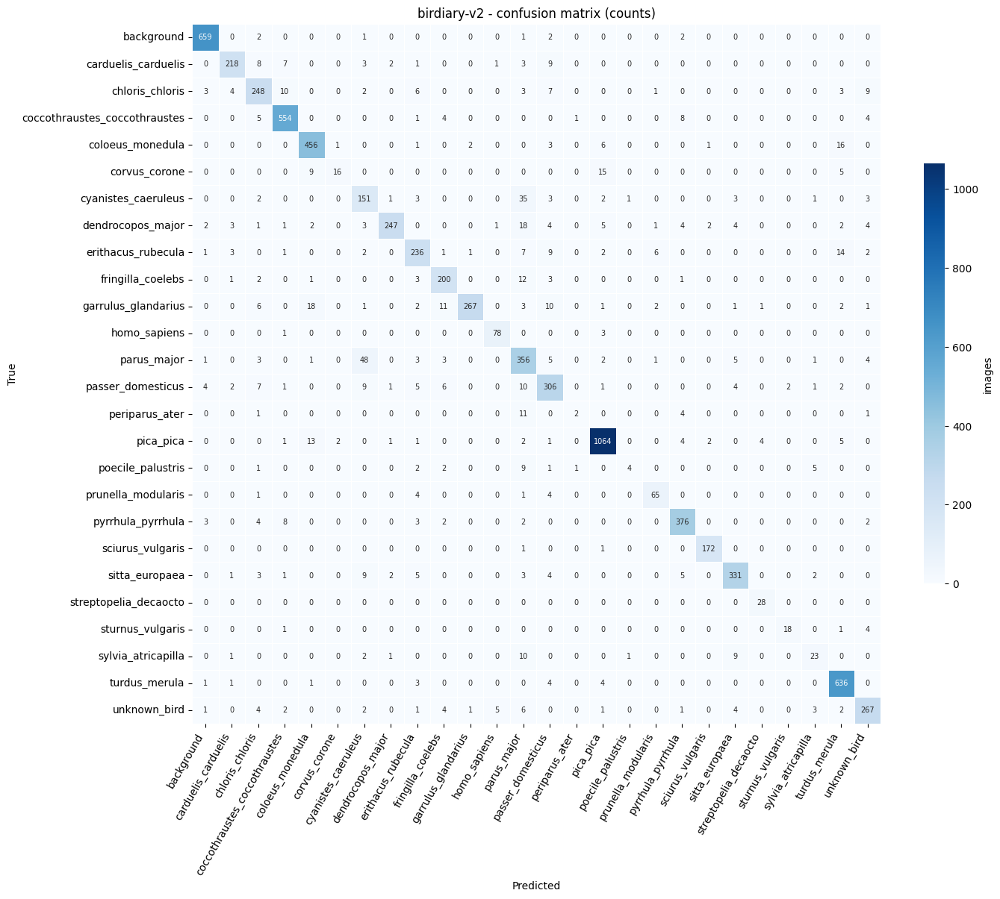

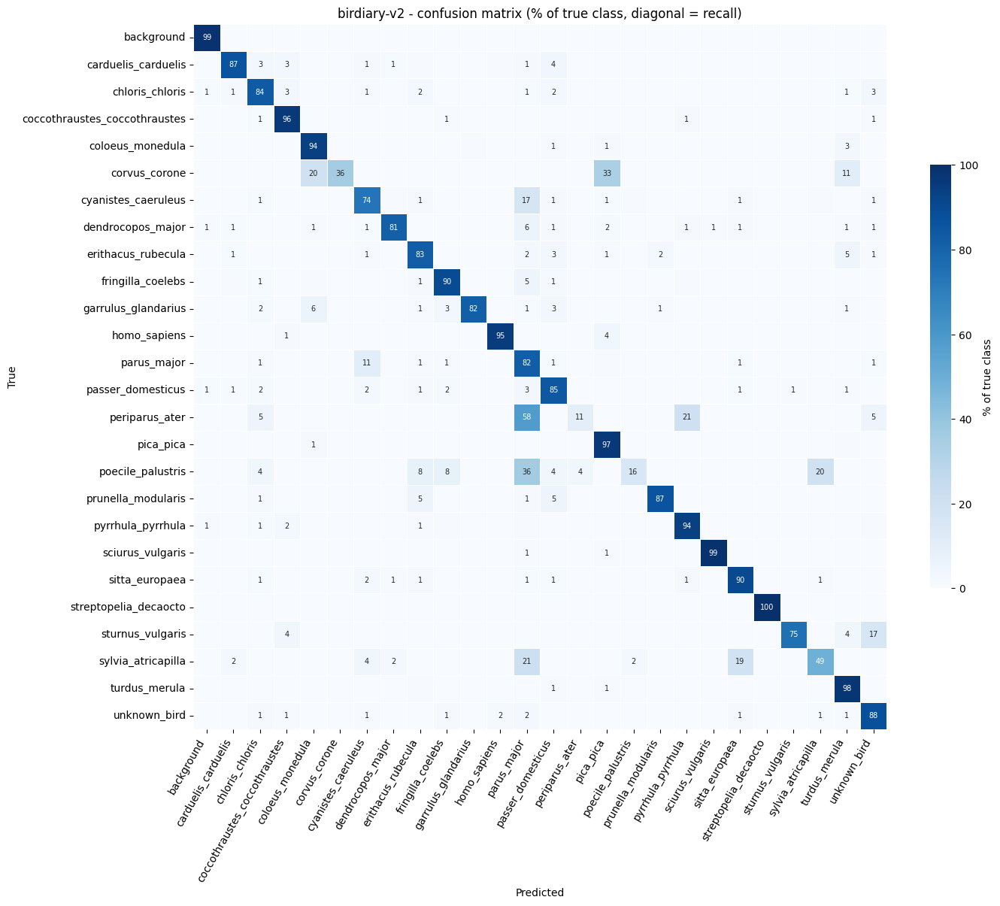

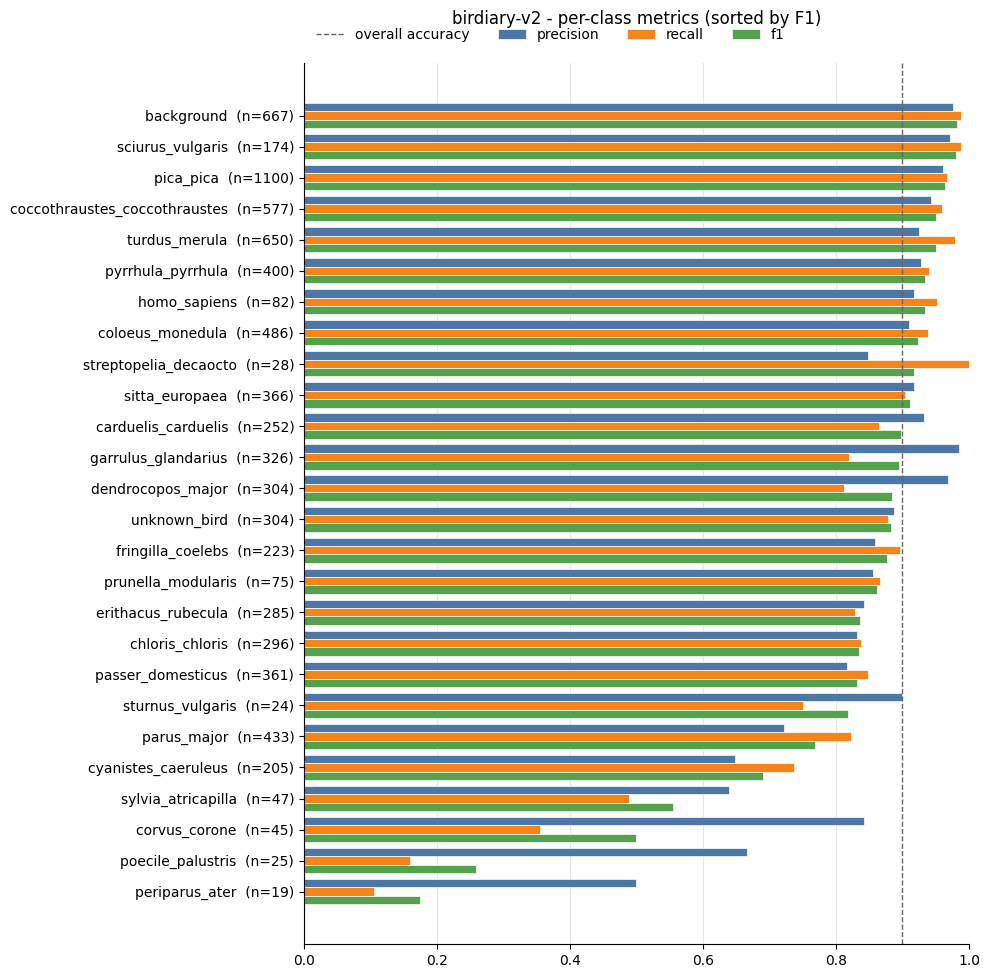

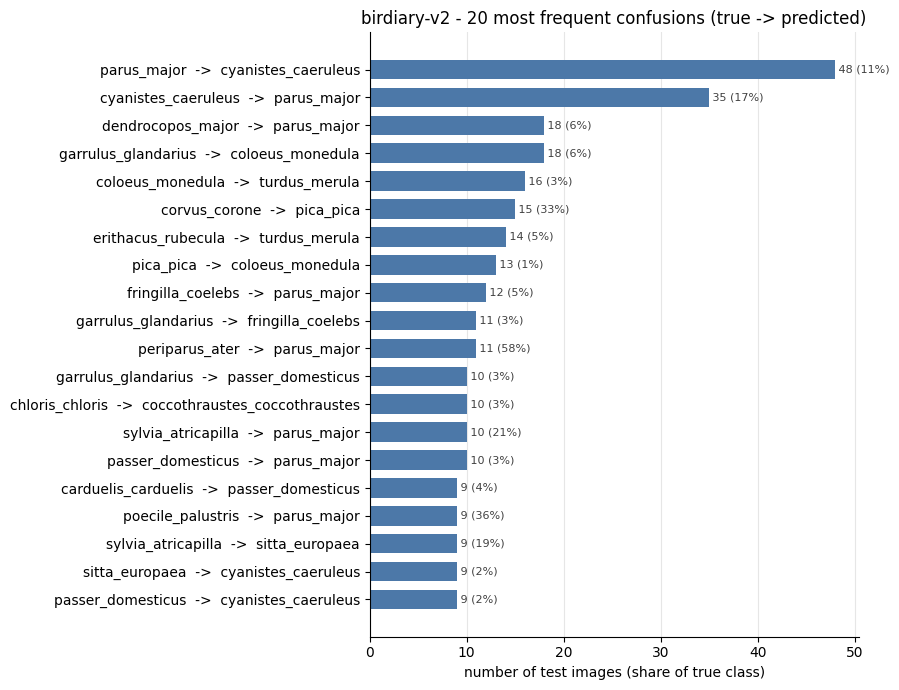

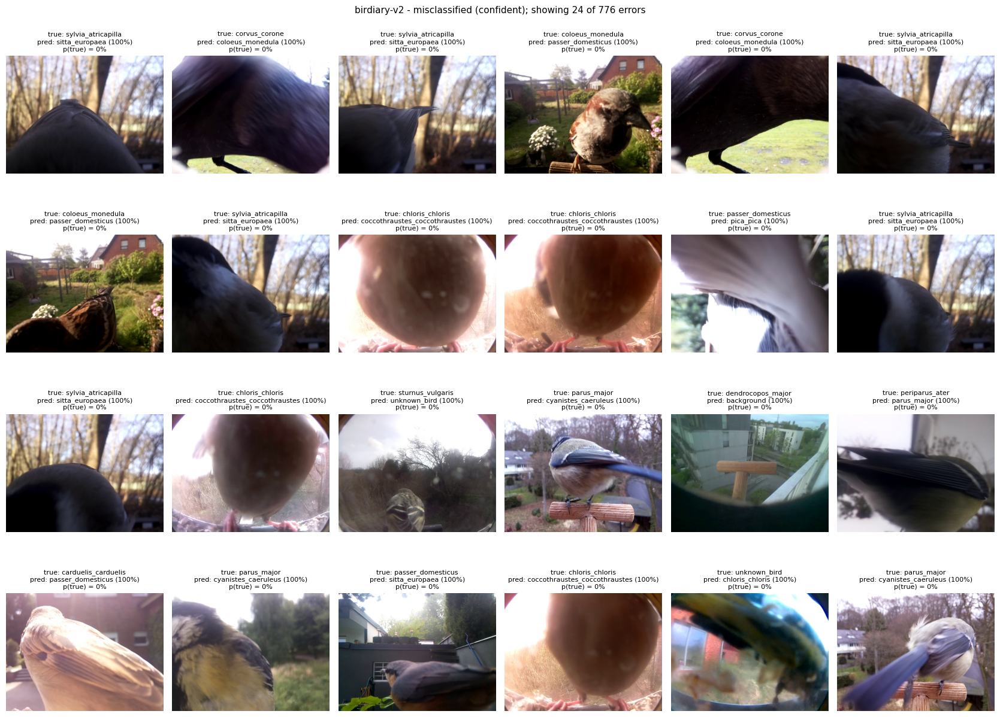

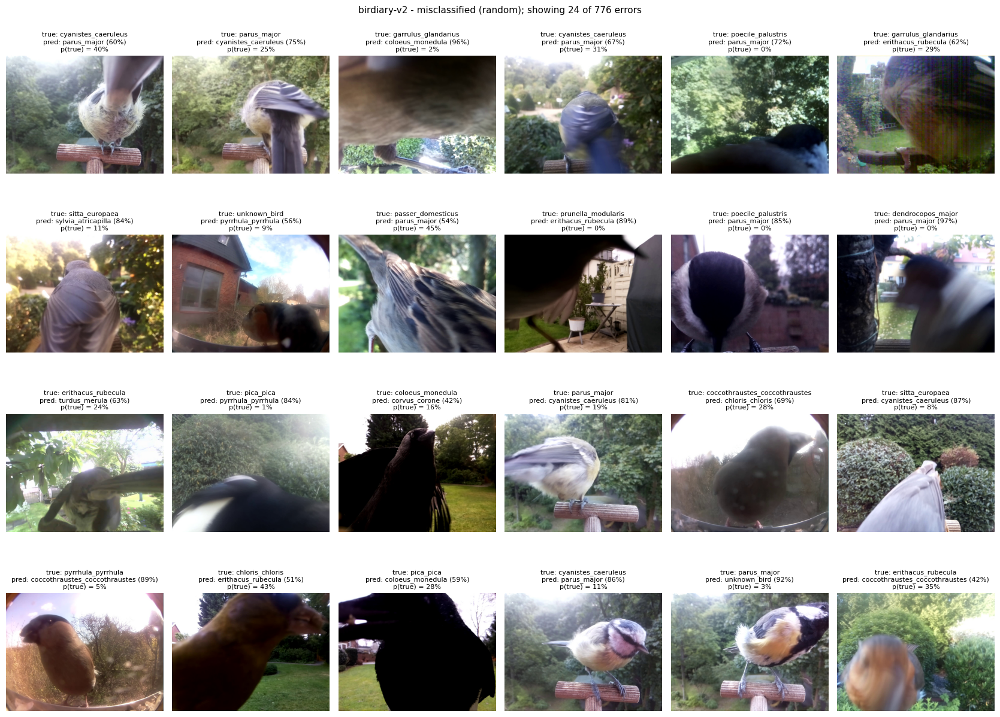

### birdiary-v2-mobilenet (mobilenetv2)
accuracy **88.90%** | balanced accuracy **78.23%** | macro F1 **0.793** | top-3 **96.79%** | 7754 test images

,support,predicted,precision,recall,f1,mean_conf_correct,n_errors,most_confused_with,share_of_class
class,,,,,,,,,
periparus_ater,19,1,1.000,0.053,0.100,0.994,18,parus_major,63.2%
poecile_palustris,25,12,0.500,0.240,0.324,0.664,19,sylvia_atricapilla,24.0%
corvus_corone,45,13,0.923,0.267,0.414,0.801,33,pica_pica,40.0%
sylvia_atricapilla,47,44,0.591,0.553,0.571,0.800,21,sitta_europaea,19.1%
cyanistes_caeruleus,205,239,0.611,0.712,0.658,0.826,59,parus_major,16.1%
sturnus_vulgaris,24,18,0.889,0.667,0.762,0.910,8,unknown_bird,25.0%
parus_major,433,452,0.750,0.783,0.766,0.872,94,cyanistes_caeruleus,13.6%
chloris_chloris,296,261,0.877,0.774,0.822,0.912,67,unknown_bird,5.7%
erithacus_rubecula,285,263,0.859,0.793,0.825,0.894,59,passer_domesticus,3.9%


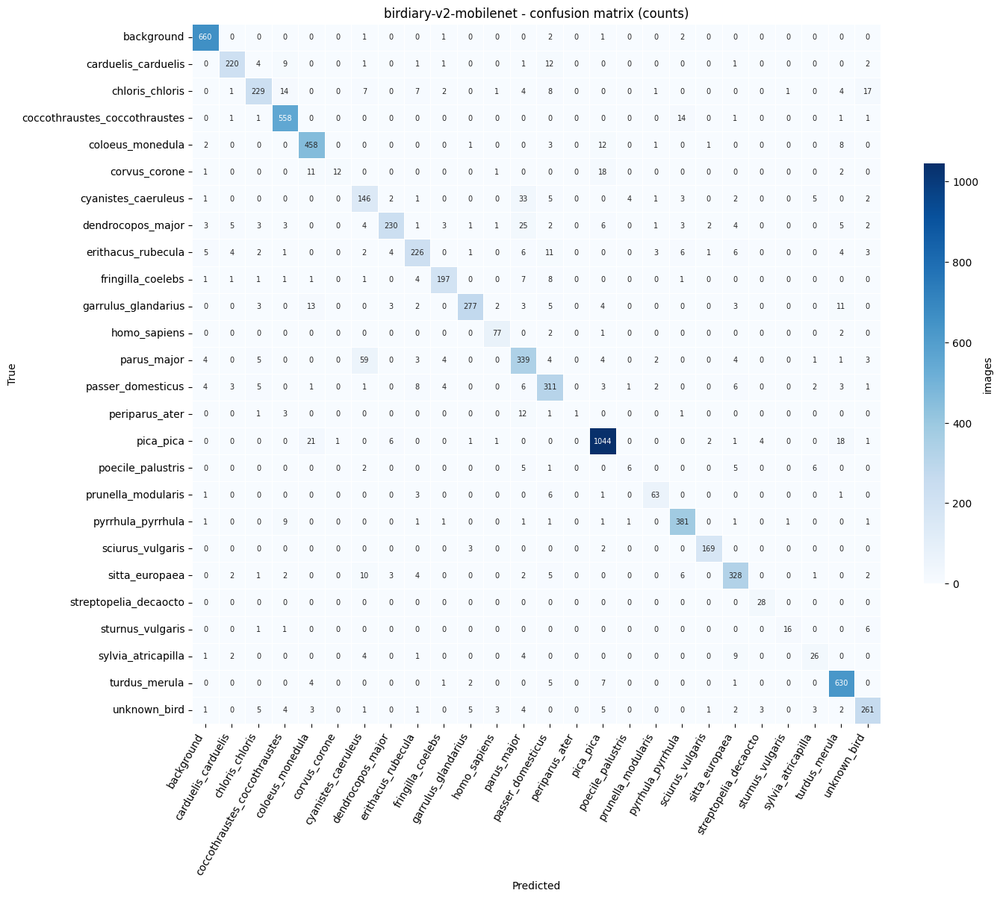

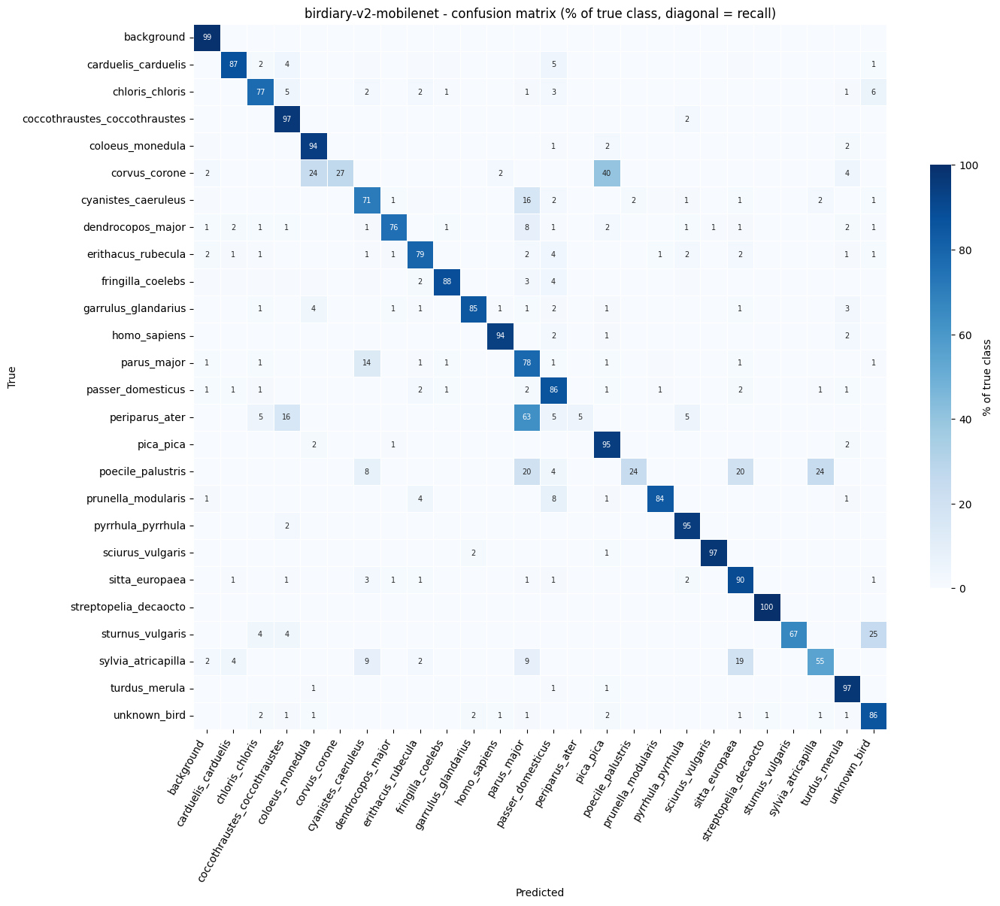

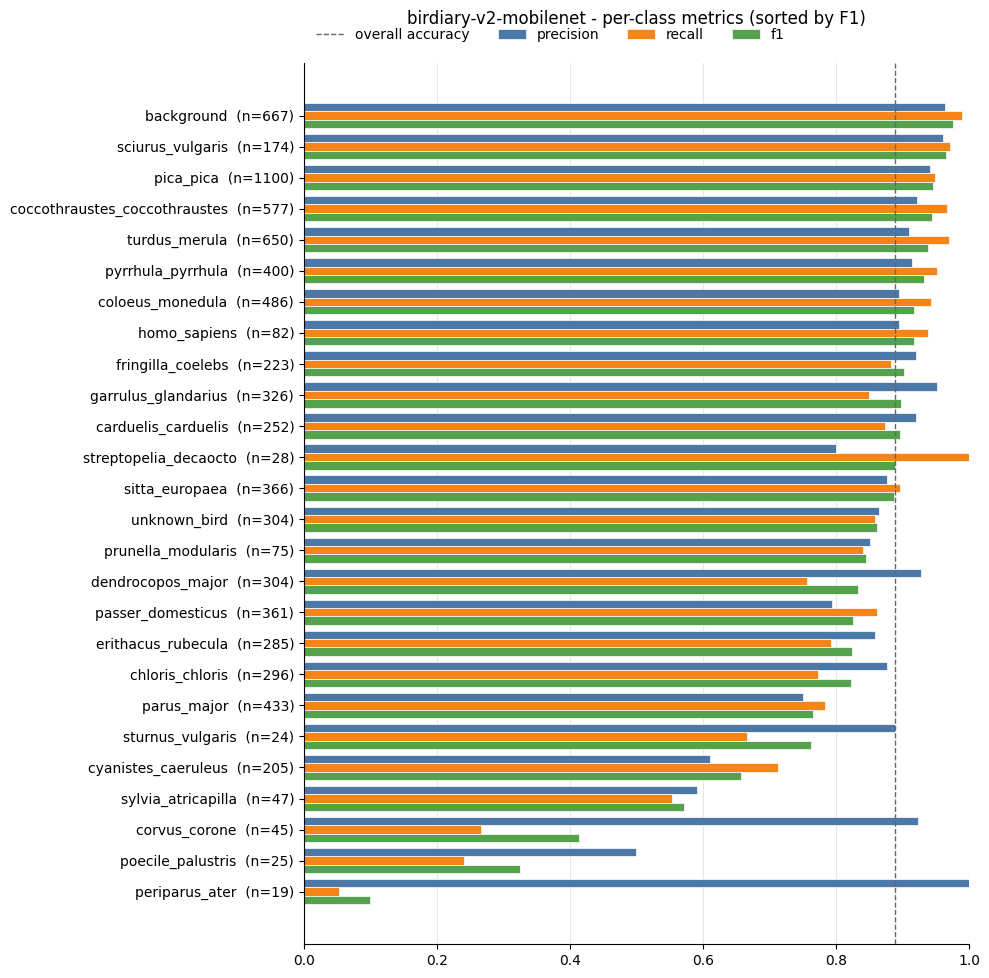

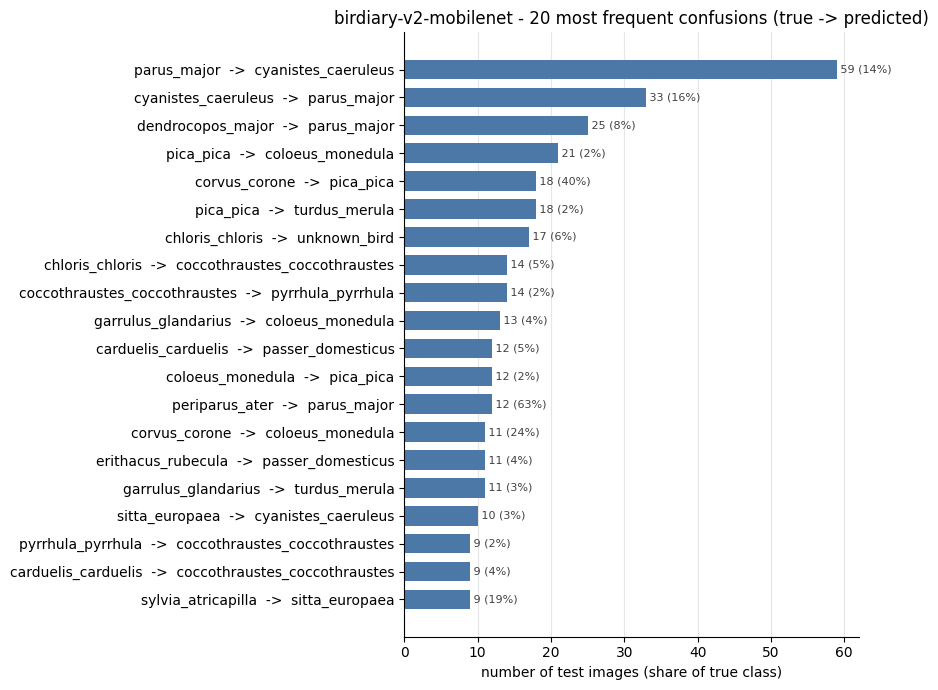

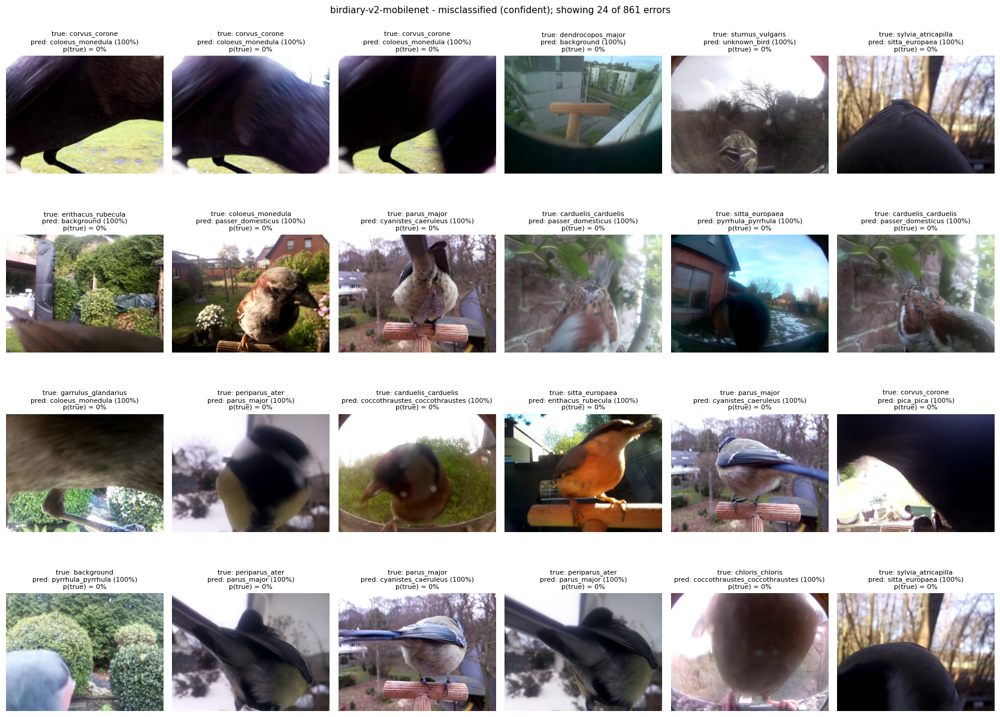

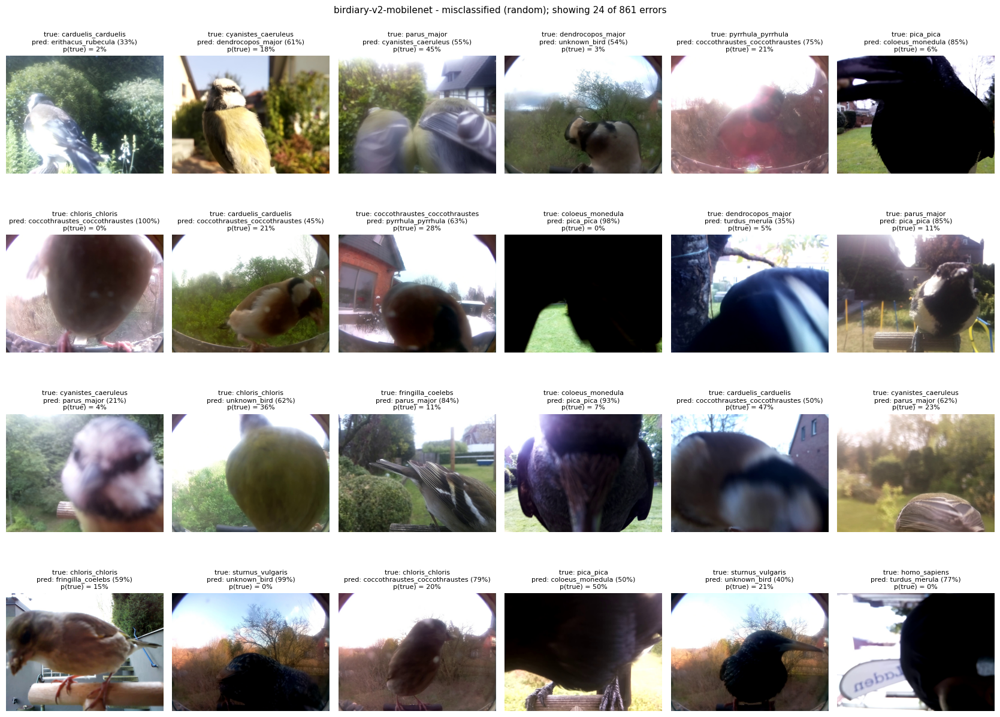

### birdiary-v2-squeezenet (mobilenet)
accuracy **89.81%** | balanced accuracy **79.45%** | macro F1 **0.812** | top-3 **97.55%** | 7754 test images

,support,predicted,precision,recall,f1,mean_conf_correct,n_errors,most_confused_with,share_of_class
class,,,,,,,,,
periparus_ater,19,5,0.600,0.158,0.250,0.758,16,parus_major,36.8%
poecile_palustris,25,6,0.667,0.160,0.258,0.641,21,parus_major,32.0%
corvus_corone,45,14,0.929,0.289,0.441,0.696,32,pica_pica,42.2%
sylvia_atricapilla,47,32,0.719,0.489,0.582,0.834,24,parus_major,19.1%
cyanistes_caeruleus,205,259,0.610,0.771,0.681,0.877,47,parus_major,15.1%
parus_major,433,472,0.742,0.808,0.773,0.901,83,cyanistes_caeruleus,12.5%
erithacus_rubecula,285,274,0.821,0.789,0.805,0.920,60,turdus_merula,5.6%
chloris_chloris,296,328,0.771,0.855,0.811,0.946,43,coccothraustes_coccothraustes,3.7%
prunella_modularis,75,64,0.891,0.760,0.820,0.910,18,erithacus_rubecula,10.7%


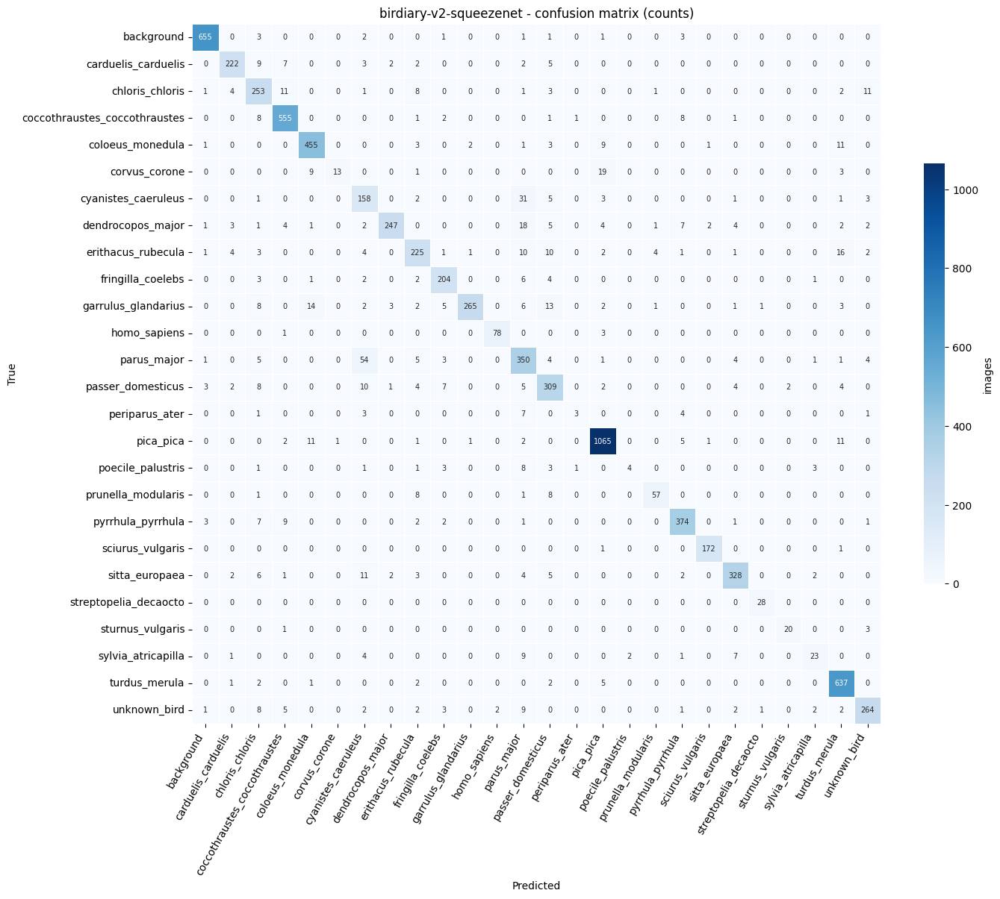

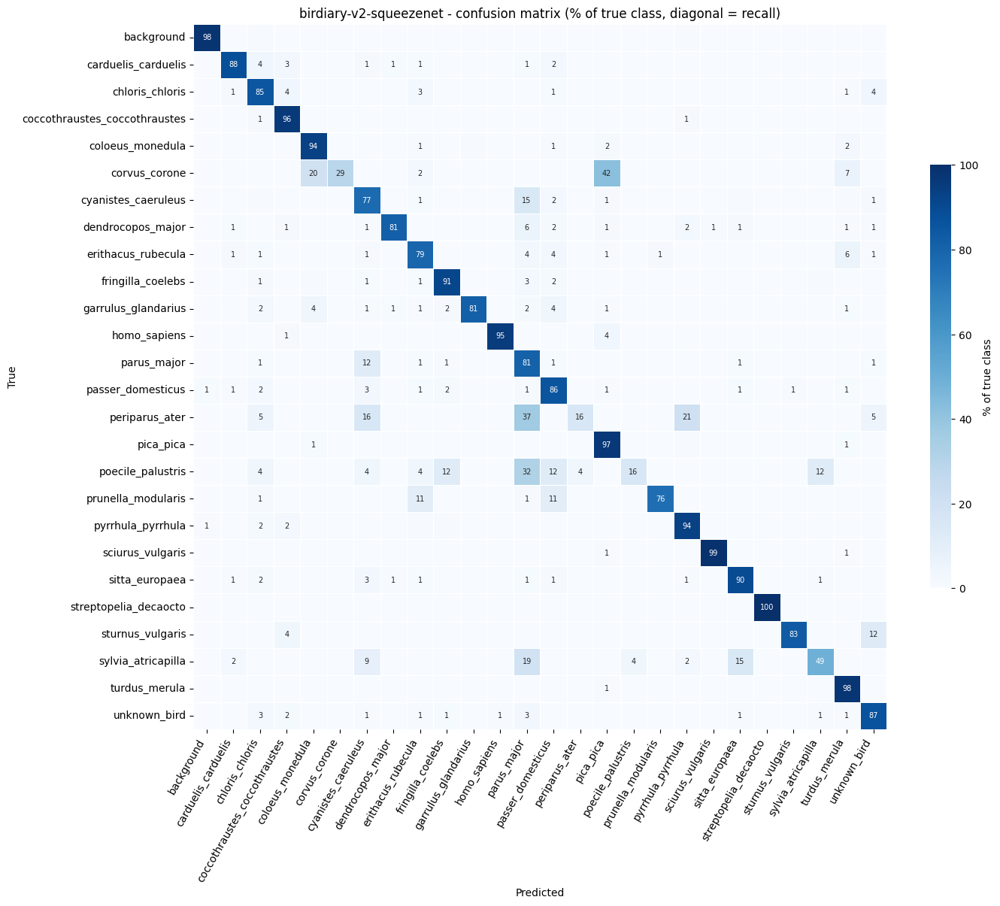

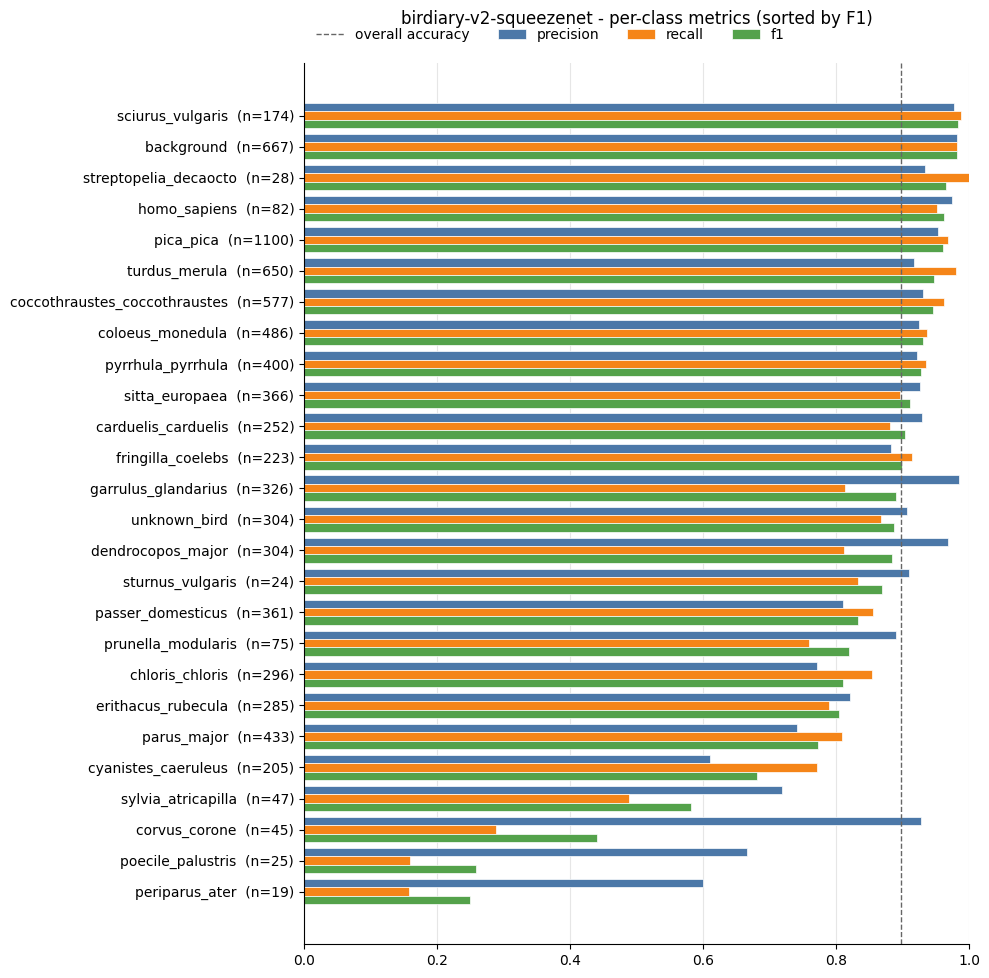

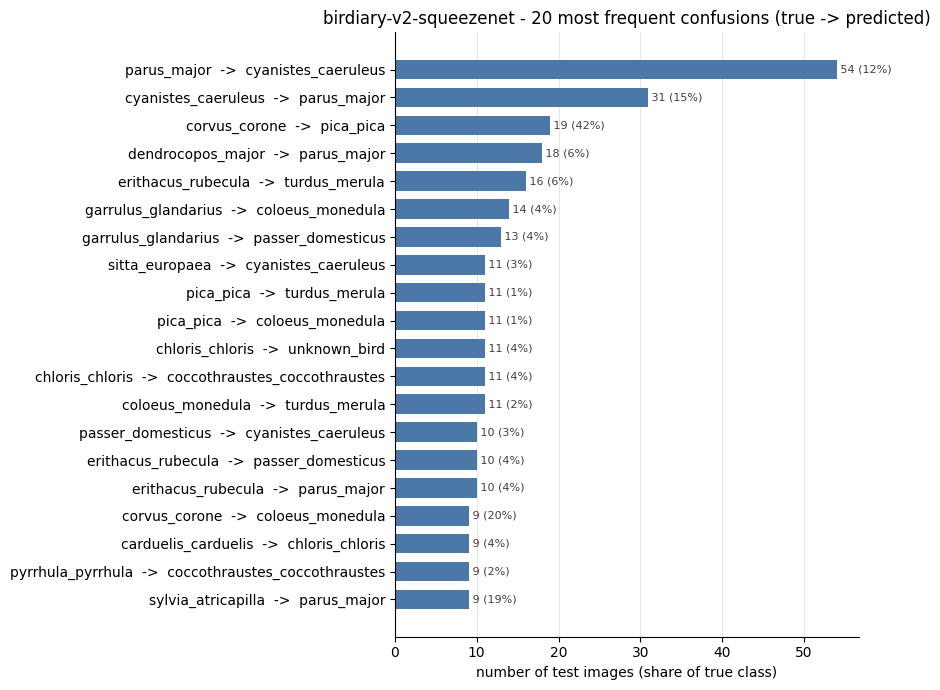

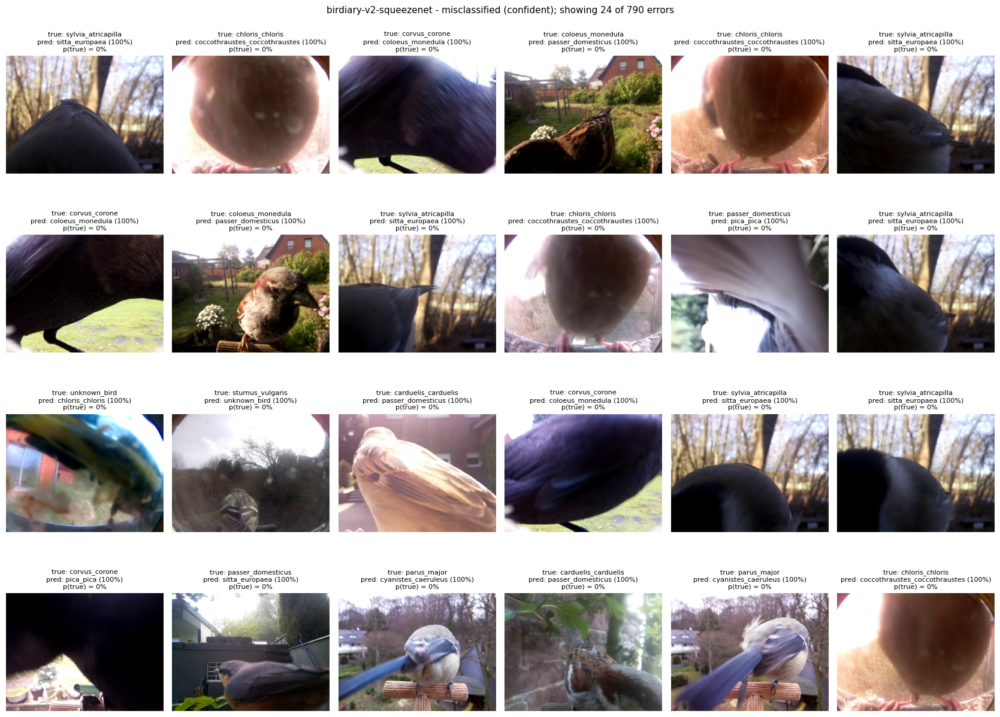

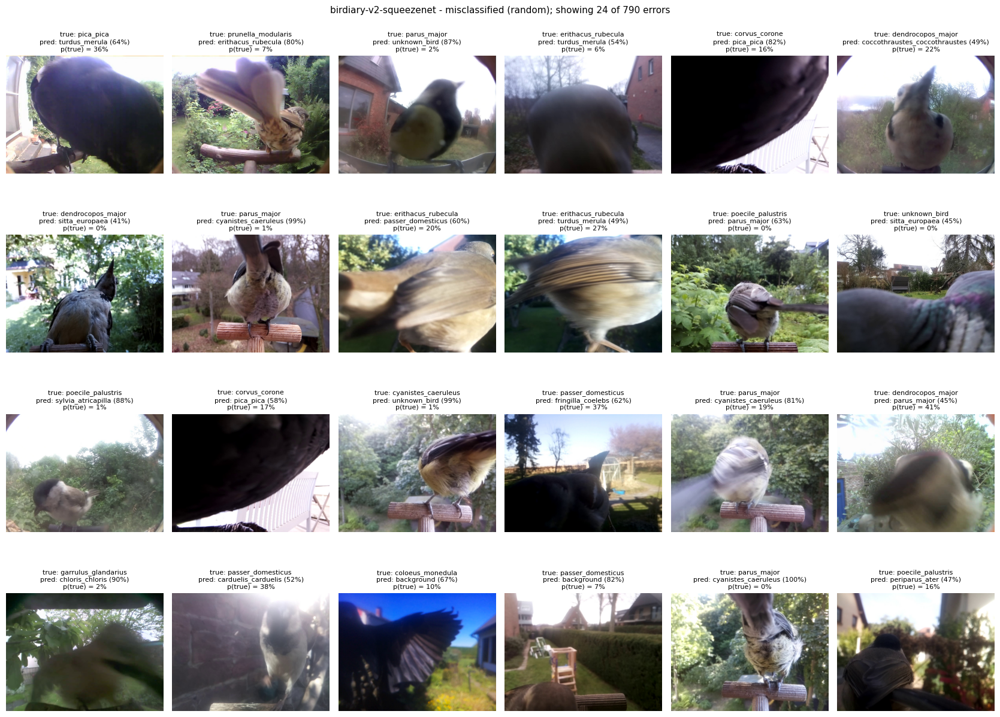

In [24]:
MODELS_TO_SHOW = list(RESULTS)  # e.g. ["birdiary-v2"]

for name in MODELS_TO_SHOW:
    r = RESULTS[name]
    entry, res, met = r["entry"], r["res"], r["met"]
    o = met["overall"]
    display(Markdown(
        f"### {name} ({entry['config'].get('model_type', '?')})\n"
        f"accuracy **{o['accuracy']:.2%}** | balanced accuracy **{o['balanced_accuracy']:.2%}** | "
        f"macro F1 **{o['macro_f1']:.3f}** | top-3 **{o['top3_accuracy']:.2%}** | "
        f"{o['n_test_images']} test images"
    ))
    display(met["per_class"].sort_values("f1").style
            .format({"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}",
                     "mean_conf_correct": "{:.3f}", "share_of_class": "{:.1%}"})
            .background_gradient(subset=["precision", "recall", "f1"], cmap="RdYlGn", vmin=0, vmax=1))
    plot_confusion_matrices(entry, res, met)
    plot_per_class(entry, met)
    plot_top_confusions(entry, met)
    show_misclassified(entry, res, met, mode="confident", save_suffix="test_errors_confident")
    show_misclassified(entry, res, met, mode="random", save_suffix="test_errors_random")

## Inspect specific confusions

Pick a model and look at the errors for a given true class and/or predicted class
(e.g. the most frequent confusion pairs from the table above).

,true,predicted,count,share_of_true_class
0,parus_major,cyanistes_caeruleus,48,0.111
1,cyanistes_caeruleus,parus_major,35,0.171
2,dendrocopos_major,parus_major,18,0.059
3,garrulus_glandarius,coloeus_monedula,18,0.055
4,coloeus_monedula,turdus_merula,16,0.033
5,corvus_corone,pica_pica,15,0.333
6,erithacus_rubecula,turdus_merula,14,0.049
7,pica_pica,coloeus_monedula,13,0.012
8,fringilla_coelebs,parus_major,12,0.054
9,garrulus_glandarius,fringilla_coelebs,11,0.034


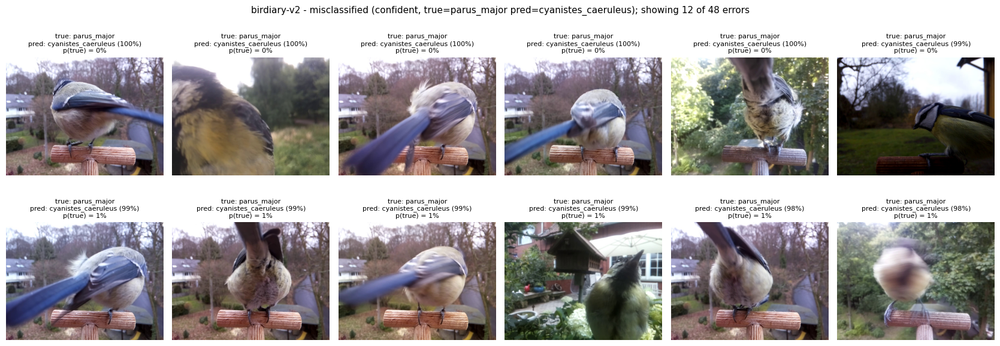

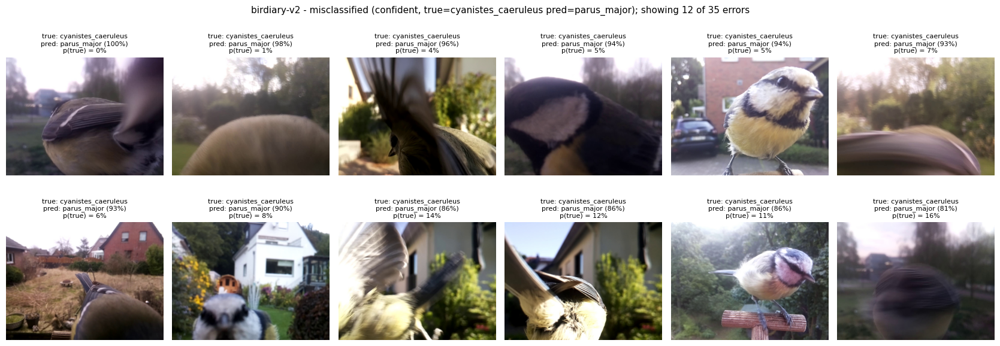

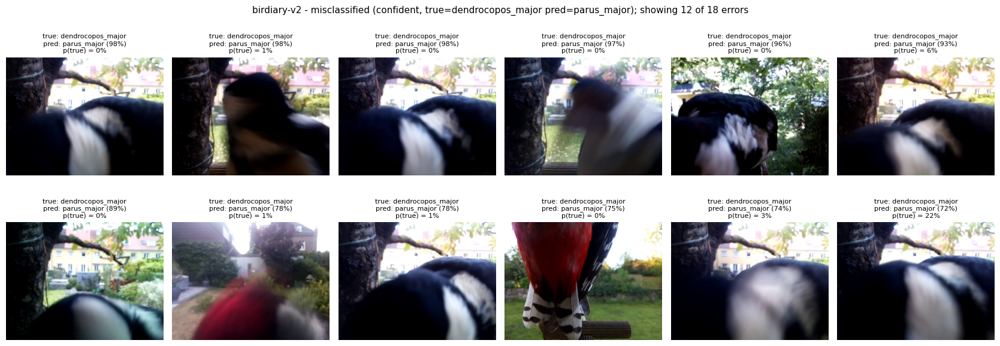

In [25]:
MODEL = next(iter(RESULTS))
r = RESULTS[MODEL]
display(r["met"]["pairs"].head(10))

# Errors of the 3 most frequent confusion pairs
for _, row in r["met"]["pairs"].head(3).iterrows():
    show_misclassified(r["entry"], r["res"], r["met"], n=12, true_class=row["true"], pred_class=row["predicted"])

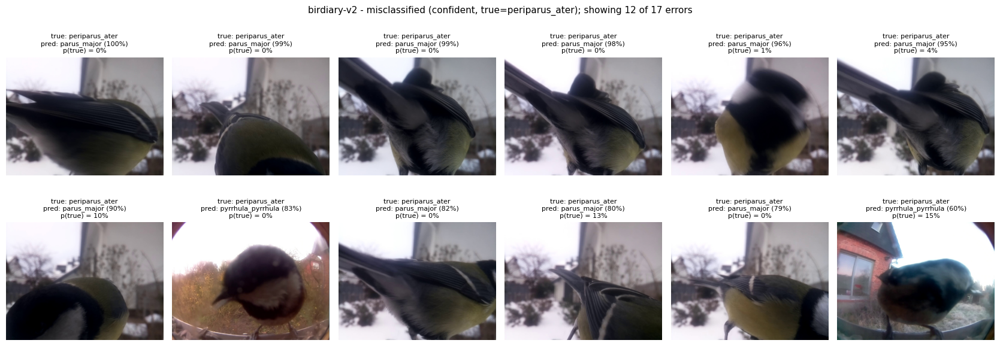

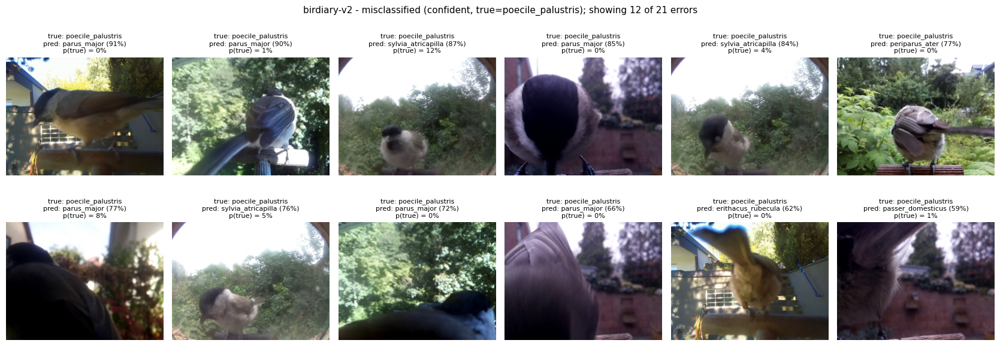

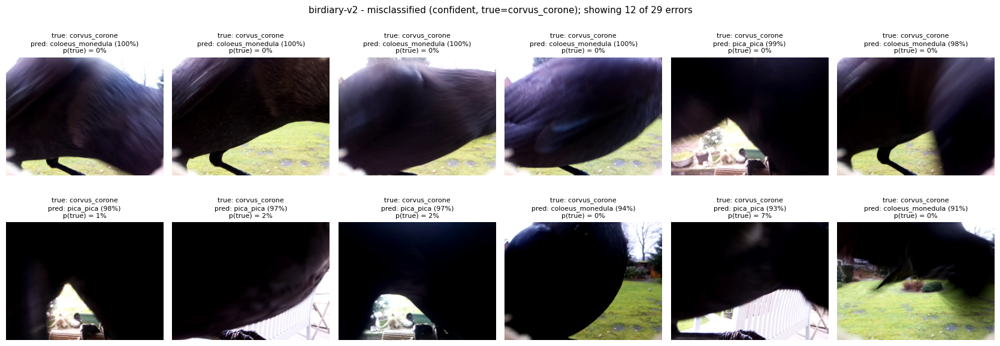

In [26]:
# Errors for the weakest classes (lowest F1), regardless of the predicted class
for cls in r["met"]["per_class"].sort_values("f1").index[:3]:
    show_misclassified(r["entry"], r["res"], r["met"], n=12, true_class=cls)

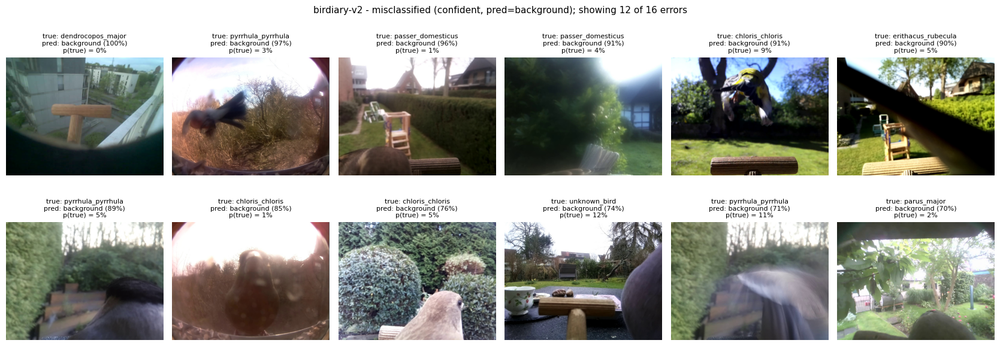

In [27]:
# Free exploration: e.g. images wrongly predicted as "background" or "unknown_bird"
show_misclassified(r["entry"], r["res"], r["met"], n=12, pred_class="background")

## Model comparison

Only meaningful once more than one model folder exists.

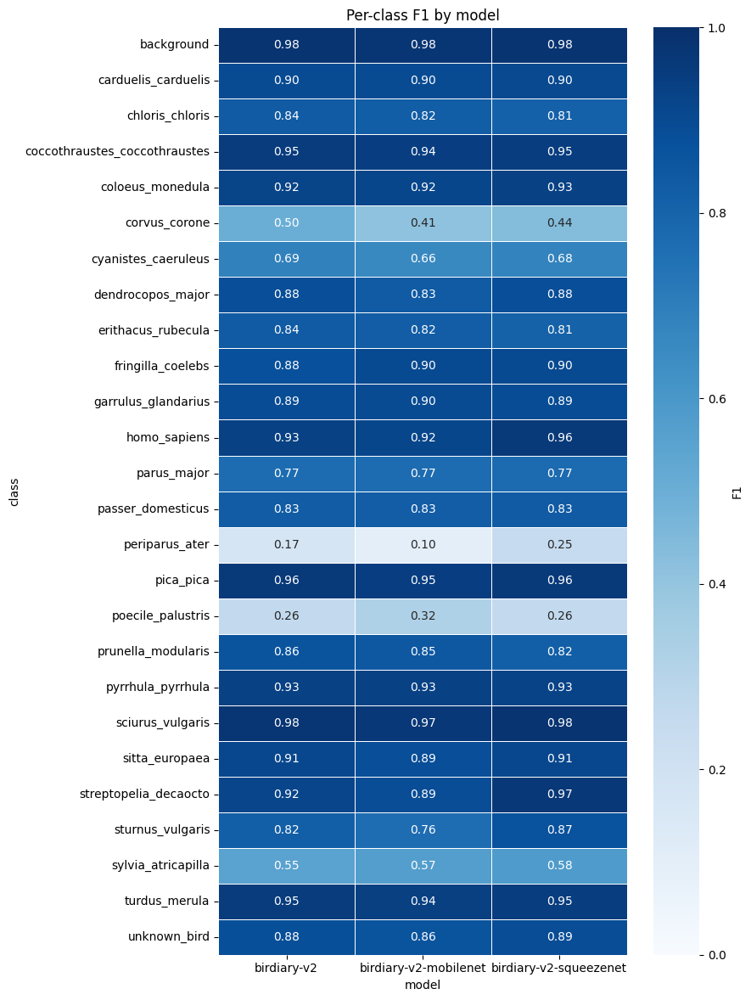

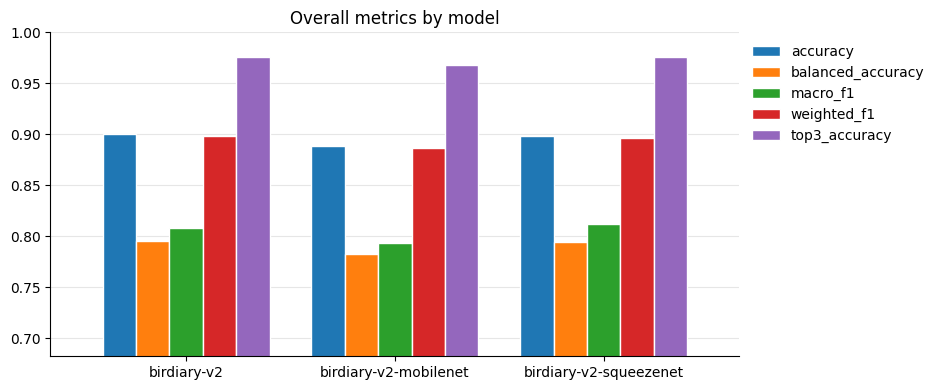

,accuracy,balanced_accuracy,macro_f1,weighted_f1,top3_accuracy
birdiary-v2-squeezenet,0.898,0.795,0.812,0.896,0.975
birdiary-v2,0.900,0.796,0.808,0.898,0.975
birdiary-v2-mobilenet,0.889,0.782,0.793,0.886,0.968


In [28]:
if len(RESULTS) > 1:
    f1 = pd.DataFrame({n: r["met"]["per_class"]["f1"] for n, r in RESULTS.items()})
    fig, ax = plt.subplots(figsize=(1.6 * len(RESULTS) + 4, 0.38 * len(f1) + 2))
    sns.heatmap(f1, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
                linewidths=0.5, linecolor="white", cbar_kws={"label": "F1"}, ax=ax)
    ax.set(title="Per-class F1 by model", xlabel="model", ylabel="class")
    fig.tight_layout()
    if SAVE_FIGURES:
        fig.savefig(os.path.join(MODELS_ROOT, "model_comparison_per_class_f1.png"), dpi=150, bbox_inches="tight")
    plt.show()

    cols = ["accuracy", "balanced_accuracy", "macro_f1", "weighted_f1", "top3_accuracy"]
    comp = pd.DataFrame({n: r["met"]["overall"] for n, r in RESULTS.items()}).T[cols]
    ax = comp.plot.bar(figsize=(1.5 * len(comp) + 5, 4), width=0.8, edgecolor="white")
    ax.set_ylim(max(0, comp.values.min() - 0.1), 1)
    ax.set_title("Overall metrics by model")
    ax.grid(axis="y", color="0.9")
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    plt.xticks(rotation=0)
    plt.legend(frameon=False, bbox_to_anchor=(1, 1))
    plt.tight_layout()
    plt.show()
    display(comp.sort_values("macro_f1", ascending=False))
else:
    print("Only one model available - nothing to compare yet.")